In [1]:
import pandas as pd

df = pd.read_csv("../src/hw1_data_analysis/bicycle_data.csv")

df.head()

,Date,"Fremont Bridge Sidewalks, south of N 34th St Total","Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk"
0,10/02/2012 01:00:00 PM,55.0,48.0,7.0
1,10/02/2012 02:00:00 PM,130.0,75.0,55.0
2,10/02/2012 03:00:00 PM,152.0,71.0,81.0
3,10/02/2012 04:00:00 PM,278.0,111.0,167.0
4,10/02/2012 05:00:00 PM,563.0,170.0,393.0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 122675 entries, 0 to 122674
Data columns (total 4 columns):
 #   Column                                                              Non-Null Count   Dtype  
---  ------                                                              --------------   -----  
 0   Date                                                                122675 non-null  str    
 1   Fremont Bridge Sidewalks, south of N 34th St Total                  122645 non-null  float64
 2   Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk  122645 non-null  float64
 3   Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk  122645 non-null  float64
dtypes: float64(3), str(1)
memory usage: 3.7 MB


### Column descriptions and data types

Each row records bicycle counts for a particular date and hour. The Date column contains the timestamp. The other three columns contain the reported total count, the west sidewalk count, and the east sidewalk count.

Date was loaded as text and should be converted to a datetime type. The count columns were loaded as float64 and each contains 30 missing values. I convert them to pandas' nullable Int64 type to represent whole-number counts while preserving missing values.

In [3]:
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%m/%d/%Y %I:%M:%S %p"
)

count_columns = df.columns[1:]
df[count_columns] = df[count_columns].astype("Int64")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 122675 entries, 0 to 122674
Data columns (total 4 columns):
 #   Column                                                              Non-Null Count   Dtype         
---  ------                                                              --------------   -----         
 0   Date                                                                122675 non-null  datetime64[us]
 1   Fremont Bridge Sidewalks, south of N 34th St Total                  122645 non-null  Int64         
 2   Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk  122645 non-null  Int64         
 3   Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk  122645 non-null  Int64         
dtypes: Int64(3), datetime64[us](1)
memory usage: 4.1 MB


In [4]:
west_col = "Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk"
east_col = "Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk"

df["Total"] = df[west_col] + df[east_col]
df["Hour"] = df["Date"].dt.hour
df["Year"] = df["Date"].dt.year

df[["Date", "Total", "Hour", "Year"]].head()

,Date,Total,Hour,Year
0,2012-10-02 13:00:00,55,13,2012
1,2012-10-02 14:00:00,130,14,2012
2,2012-10-02 15:00:00,152,15,2012
3,2012-10-02 16:00:00,278,16,2012
4,2012-10-02 17:00:00,563,17,2012


In [5]:
df_2016 = df[df["Year"] == 2016].copy()

df_2016[["Date", "Total", "Hour", "Year"]].head()

,Date,Total,Hour,Year
28451,2016-01-01 00:00:00,18,0,2016
28452,2016-01-01 01:00:00,15,1,2016
28453,2016-01-01 02:00:00,11,2,2016
28454,2016-01-01 03:00:00,7,3,2016
28455,2016-01-01 04:00:00,2,4,2016


In [6]:
print("Rows in 2016:", len(df_2016))
print("Years included:", df_2016["Year"].unique())

Rows in 2016: 8784
Years included: [2016]


In [7]:
df.isna().sum()

Date                                                                   0
Fremont Bridge Sidewalks, south of N 34th St Total                    30
Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk    30
Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk    30
Total                                                                 30
Hour                                                                   0
Year                                                                   0
dtype: int64

In [8]:
df.loc[
    df["Total"].isna(),
    ["Date", west_col, east_col, "Total"]
].head(10)

,Date,"Fremont Bridge Sidewalks, south of N 34th St Cyclist West Sidewalk","Fremont Bridge Sidewalks, south of N 34th St Cyclist East Sidewalk",Total
3805,2013-03-10 02:00:00,<NA>,<NA>,<NA>
6116,2013-06-14 09:00:00,<NA>,<NA>,<NA>
6117,2013-06-14 10:00:00,<NA>,<NA>,<NA>
12541,2014-03-09 02:00:00,<NA>,<NA>,<NA>
21277,2015-03-08 02:00:00,<NA>,<NA>,<NA>
22342,2015-04-21 11:00:00,<NA>,<NA>,<NA>
22343,2015-04-21 12:00:00,<NA>,<NA>,<NA>
22344,2015-04-21 13:00:00,<NA>,<NA>,<NA>
30181,2016-03-13 02:00:00,<NA>,<NA>,<NA>
38917,2017-03-12 02:00:00,<NA>,<NA>,<NA>


In [9]:
clean_df = df.dropna(subset=["Date", "Total"]).copy()

print("Original rows:", len(df))
print("Rows used for analysis:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

clean_df[["Date", "Total"]].isna().sum()

Original rows: 122675
Rows used for analysis: 122645
Rows removed: 30


Date     0
Total    0
dtype: int64

In [10]:
expected_hours = pd.date_range(
    start=df["Date"].min(),
    end=df["Date"].max(),
    freq="h"
)

missing_hours = expected_hours.difference(
    pd.DatetimeIndex(df["Date"])
)

print("Hours absent from CSV:", len(missing_hours))
missing_hours[:10]

Hours absent from CSV: 0


DatetimeIndex([], dtype='datetime64[us]', freq='h')

### Missing data

The dataset contains 30 rows with missing total counts. No hourly timestamps are absent between the earliest and latest timestamps in the CSV.

I excluded rows with missing dates or total counts, leaving 122,645 rows in `clean_df`. Missing counts were not replaced with zero because a missing observation does not mean that no bicycles crossed the bridge. The following analysis uses valid observations from all years.

In [11]:
hourly_mean = clean_df.groupby("Hour")["Total"].mean()

hourly_mean

Hour
0      11.253229
1       6.424462
2       4.480965
3       3.441879
4        6.94775
5      22.972016
6       77.45362
7     192.581605
8     280.809785
9     175.033666
10    106.010765
11    100.616243
12     108.04227
13    114.432401
14    125.929969
15    158.305556
16    239.368936
17    349.214397
18    236.192488
19    126.815336
20     75.551839
21     50.928013
22     32.570618
23     20.569836
Name: Total, dtype: Float64

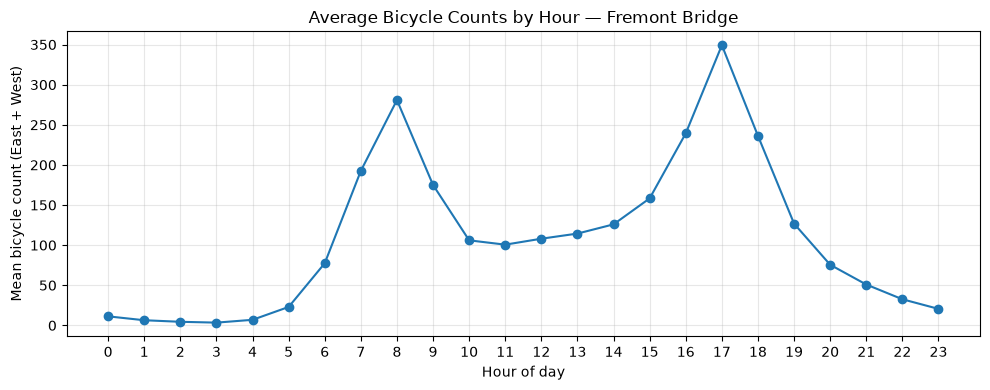

In [12]:
import matplotlib.pyplot as plt

hourly_mean.plot(kind="line", marker="o", figsize=(10, 4))

plt.title("Average Bicycle Counts by Hour — Fremont Bridge")
plt.xlabel("Hour of day")
plt.ylabel("Mean bicycle count (East + West)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
busiest_hour = hourly_mean.idxmax()
busiest_mean = hourly_mean.max()

print("Busiest hour:", busiest_hour)
print("Mean bicycle count:", round(busiest_mean, 2))

Busiest hour: 17
Mean bicycle count: 349.21


### Busiest hour

After excluding missing counts, I calculated the mean total bicycle count for each hour using data from all years. The busiest hour is 17:00 (5 PM), with an average of approximately 349.21 bicycles across both sidewalks. I identified this hour using `idxmax()` on the hourly means.